# TOPol-Mech V1 axis discovery + NLA -- Amazon reviews

This notebook is the step-by-step companion to the **discovery pipeline**
of TOPol: it takes a human defined
contextual-boundary (CB) polarity vector as ground truth for the sentiment polarity vector across topics, and asks the following question of the SAME activation space --

> *is a topic's regime-A -> regime-B drift really just ONE direction and specifically sentiment,
> are there additional dimensions, independent from the sentiment polar vector, and reproducible structure hiding alongside them?*

**Dataset: Amazon product reviews only** -- ratings <= 2 (regime A) vs >= 4
(regime B), middle band dropped for experimental clarity. This is deliberate: dropping the middle band should make sentiment the
dominant, easy-to-find direction in each topic's cloud.

## What "axis discovery" adds

The human defined CB designed to capture sentiment polarity, gives ONE vector per topic: $v^t_{CB} = \mu_B - \mu_A$, the
plain difference of the regime-A and regime-B document centroids, at ONE
layer of the transformer model, layer chosen by how well a linear probe separates A from B. That is a good
estimator of the reference sentiment polarity drift, but it cannot tell whether a topic's
cloud has a other independent and real axis of variation. The axis discovery process looks for that: at every cached residual layer,
it centres a topic's documents on their own mean, splits the centred cloud in
two with cosine 2-means, records that split, projects the direction that
split it out of the cloud, and repeats -- a small number of times, always
finding directions that are orthogonal to every one found before it (because
each one is found only after removing what came before). Every layer's set of
candidate splits for a topic is then deduplicated across layers (the same
split showing up at layers 14, 15 and 16 is one contrast, not three), given a
full depth profile across every cached layer, and -- the one filter in this
whole pipeline -- gated by asking whether the SAME split reappears
independently when the topic's documents are cut in half and analysed
separately. Only splits that pass that split-half stability test are
reported as real.

## How this notebook is organised

This is a **standalone notebook** -- everything it needs, it computes itself
(Part 2 covers the CB polarity vector: corpus, layer choice, topics, field).
It is also the ONLY notebook in this repository: every step below has a
CLI-script equivalent in `scr/scripts/`, numbered in the exact order this
notebook calls them, so you can reproduce any part of it outside Jupyter.
Every code cell below is annotated with a comment naming that script
equivalent (or "notebook-only" where none exists) and the run-directory
folder its outputs land in.

| # | Part | Script equivalent | Saves to |
|---|------|-------------------|----------|
| 0 | Setup | -- | -- |
| 1 | Config & run directory | `scripts/_common.py` (shared helper) | `config.json` |
| 2 | Corpus, layer, topics, CB field | `01_extract_representations.py`, `02_select_layer.py`, `03_cluster_manifold.py`, `04_reconstruct_field.py` | `objects/`, `figures/` |
| 3 | Activation caching | `05_topol_cache_activations.py` | `objects/topol_acts_*` |
| 4 | Discovery + the gate | `06_topol_discovery.py` | `objects/topol_gate_results.pkl` |
| 5 | Field assembly | `07_topol_field_assembly.py` | `objects/topol_field_summary.json` |
| 6 | Baseline comparison | `08_topol_baseline_compare.py` | `objects/topol_baseline_comparison.json` |
| 7 | Reporting | `08_topol_baseline_compare.py` (same script) | `objects/topol_report_full.json`, `tables/topol_report_*` |
| 8 | NLA interrogation | notebook-only (no script yet) | `objects/topol_nla_*`, `tables/topol_nla_*` |
| 9 | Summary | -- | -- |

**Prerequisites**: a GPU with the `google/gemma-3-4b-pt` weights reachable,
and `data/amazon_reviews_full.pkl` present (run
`python scripts/00_prepare_data.py --dataset amazon_reviews` once if it
is not). See `README_pipeline_2.md` next to this notebook for the full
map from every step to its `topolm` module and script equivalent.

## 0 - Setup

In [1]:
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"   # must be set before CUDA init

import sys, gc, torch
gc.collect(); torch.cuda.empty_cache()

print("CUDA available :", torch.cuda.is_available())
print("device count   :", torch.cuda.device_count())
if torch.cuda.is_available():
    print("device name    :", torch.cuda.get_device_name(0))
print("python exe     :", sys.executable)
print("torch          :", torch.__version__, "| cuda", torch.version.cuda)

import transformers
print("transformers   :", transformers.__version__)

CUDA available : True
device count   : 1
device name    : NVIDIA A100-PCIE-40GB
python exe     : /home/users/g/gomeztei/scratch/TOPOL/bin/python
torch          : 2.6.0+cu124 | cuda 12.4
transformers   : 5.14.1


### Model weights: skip the download if they're already there

`google/gemma-3-4b-pt` only needs to be downloaded once. The next cell checks
`cache_path` (a `~/scratch/hf_cache` folder by default -- point it at wherever
your weights already live if that's not it) for a complete local snapshot
first; if one is found, it's used directly and NOTHING is downloaded. A
download only happens the first time, when no local snapshot exists yet.

In [2]:
import glob
from huggingface_hub import snapshot_download

MODEL_ID = "google/gemma-3-4b-pt"
cache_path = os.path.expanduser("~/scratch/hf_cache")
os.makedirs(cache_path, exist_ok=True)


def find_local_snapshot(repo_id, cache_dir):
    """Local snapshot path for `repo_id` under `cache_dir`, if a complete
    download already exists there -- else None. Checked BEFORE any download
    is attempted."""
    folder_name = "models--" + repo_id.replace("/", "--")
    matches = glob.glob(os.path.join(cache_dir, folder_name, "snapshots", "*"))
    return matches[0] if matches else None


gemma_snapshot = find_local_snapshot(MODEL_ID, cache_path)
if gemma_snapshot is not None:
    print(f"[cache] {MODEL_ID} already present in {cache_path} -- skipping download")
else:
    print(f"{MODEL_ID} not found in {cache_path} -- downloading now (one-time)...")
    gemma_snapshot = snapshot_download(repo_id=MODEL_ID, cache_dir=cache_path)
    print("downloaded to:", gemma_snapshot)

print("model snapshot path:", gemma_snapshot)

[cache] google/gemma-3-4b-pt already present in /home/users/g/gomeztei/scratch/hf_cache -- skipping download
model snapshot path: /home/users/g/gomeztei/scratch/hf_cache/models--google--gemma-3-4b-pt/snapshots/cc012e0a6d0787b4adcc0fa2c4da74402494554d


In [3]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


def find_repo_root(start):
    p = os.path.abspath(start)
    for _ in range(6):
        if os.path.isdir(os.path.join(p, "topolm")):
            return p
        if os.path.isdir(os.path.join(p, "scr", "topolm")):
            return os.path.join(p, "scr")
        p = os.path.dirname(p)
    return None


REPO_ROOT = find_repo_root(os.getcwd())
if REPO_ROOT is None:
    raise RuntimeError(f"Could not locate the topolm package starting from {os.getcwd()}")
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

from topolm.config import default_config
from topolm.store import RunStore
from topolm.backends import make_backend
from topolm import (data as D, manifold as M, field as F, viz as V,
                    topol_activations as TA, topol_axes as AX, topol_gate as TG,
                    topol_report as TR, nla as NLA, pipeline as P)

print("cwd:", os.getcwd())
print("topolm imported from:", REPO_ROOT)

cwd: /home/users/g/gomeztei/topol_3
topolm imported from: /home/users/g/gomeztei/topol_3/scr


Small helpers used throughout:

* `show_fig` -- save a figure once, display it exactly once (Jupyter's inline
  backend auto-displays every open figure at cell end; leaving `fig` as a
  trailing expression too would show it twice).
* `have` -- has this run already computed object `name`? (checks the
  `RunStore` manifest, not the Python kernel's variables -- works across
  kernel restarts, so re-running this notebook top-to-bottom reloads
  finished steps from disk instead of redoing GPU work.)
* `load_table` -- reload a `store.save_table` CSV (saved under `tables/`)
  by its registered name.

In [4]:
def show_fig(store, name, fig, meta=None):
    """`store.save_fig` writes name.pdf + name.png under this run's figures/
    folder, then this displays it inline and closes it."""
    store.save_fig(name, fig, meta=meta)
    display(fig)
    plt.close(fig)


def have(store, *names):
    return all(n in store.manifest["entries"] for n in names)


def load_table(store, name):
    """Reads back a CSV under this run's tables/ folder by its registered name."""
    return pd.read_csv(os.path.join(store.dir, store.manifest["entries"][name]["path"]))


pd.set_option("display.max_colwidth", 100)

## 1 - Configuration & run directory

*Script equivalent: `scripts/_common.py`'s `build_config`/`open_new_store`
(the shared setup every numbered script goes through). Saves to: this run's
`config.json`, at the root of its run directory.*

**Full dataset, not a subset.** `cfg.corpus.n_per_class` is set to `None`
below -- the CB rule (rating <= 2 vs >= 4, middle band dropped) still
applies, and the two regimes are still balanced against each other (that
balance is a data-prep invariant, not something this notebook changes), but
`None` removes the artificial 5000-per-class cap `CorpusConfig`'s default
carries, so every review meeting the rating/length rule is used, balanced
down only as far as the smaller regime's own true count requires -- not to
an arbitrary fixed number.

### `discovery` config, explained

These fields (`Config.discovery`, a `DiscoveryConfig`) control every axis-
discovery step (Parts 3-7):

| field | default | meaning |
|---|---|---|
| `layer_stride` | 2 | cache every 2nd residual layer (plus layer 0, the last layer, and the CB-chosen layer, always) -- the main memory/compute lever |
| `max_depth` | 4 | recursion depth of the per-topic, per-layer deflation sequence |
| `min_cluster_size` | 30 | stop recursing once a 2-means split's smaller side falls below this many documents |
| `ari_merge` | 0.7 | cross-layer dedup: partitions with average-linkage ARI similarity >= this merge into one contrast |
| `stability_threshold` | 0.6 | split-half gate: a contrast passes if its matched half-vs-half \|cos\| at l* is >= this |
| `excess_cos_threshold` | 0.3 | baseline comparison: a gate-passing axis counts as "excess" if \|cos\| to $v_{CB}$ is below this |
| `ref_layer` | `None` | fixed layer for cross-topic pooling; `None` -> the layer Part 2's probe-separability step chose |

In [5]:
cfg = default_config(dataset="amazon_reviews")
cfg.backend = "gemma"
cfg.stats.n_permutations = 1000
cfg.runs_dir = os.path.join(REPO_ROOT, "runs")
cfg.model.name = gemma_snapshot   # a concrete local path (checked/downloaded above)

cfg.corpus.n_per_class = None   # full dataset -- see markdown above

# discovery.* defaults are printed here so every run's config.json records
# exactly what was used -- change any of these BEFORE running Part 3 onward.
print("discovery config:", cfg.discovery)
print("corpus config:", cfg.corpus)

data_dir = os.path.join(os.path.dirname(REPO_ROOT), "data")
backend = make_backend(cfg)

# tag="pipeline_2": this notebook's own run directory. Re-running this
# notebook later (same dataset, same tag) resumes it via `have(store, ...)`.
store = RunStore(cfg.runs_dir, "amazon_reviews", tag="pipeline_2", resume=True)
store.save_config(cfg)   # -> <run dir>/config.json

print("run dir:", store.dir)
print("model:", cfg.model.name, "| d_model", backend.d_model, "| layers", backend.n_layers)

discovery config: DiscoveryConfig(layer_stride=2, max_depth=4, min_cluster_size=30, ari_merge=0.7, stability_threshold=0.6, excess_cos_threshold=0.3, ref_layer=None, sentiment_corr_threshold=0.2)
corpus config: CorpusConfig(speeches_path=None, breakpoint='2007-05-01', window_years=None, speech_min_chars=500, max_docs=600, amazon_path=None, n_per_class=None, negative_max=2, positive_min=4, review_min_chars=100)


Loading weights:   0%|          | 0/883 [00:00<?, ?it/s]

run dir: /home/users/g/gomeztei/topol_3/scr/runs/amazon_reviews_pipeline_2
model: /home/users/g/gomeztei/scratch/hf_cache/models--google--gemma-3-4b-pt/snapshots/cc012e0a6d0787b4adcc0fa2c4da74402494554d | d_model 2560 | layers 34


## 2 - The CB polarity vector: corpus, layer, topics, field

*Script equivalents: `01_extract_representations.py` (corpus + layer-selection
activations), `02_select_layer.py` (chosen layer), `03_cluster_manifold.py`
(topics), `04_reconstruct_field.py` (the CB field itself). Saves to:
`objects/texts.pkl`, `objects/labels.npz`, `objects/layer_selection.json`,
`objects/embeddings.npz`, `objects/cluster_labels.npz`,
`objects/coords_2d.npz`, `objects/field.pkl`, plus `figures/01_layer_selection.*`
and `figures/02_field_2d.*`.*

Four things happen here, each cached independently via `have(store, ...)`:
load the corpus and its contextual boundary; choose the residual layer by
A/B probe separability; segment into topics (UMAP + Leiden); reconstruct the
CB polarity field $v^t_{CB} = \mu^t_B - \mu^t_A$ per topic. Everything from
Part 3 onward is built on top of these four objects.

In [6]:
# equivalent to: scripts/01_extract_representations.py (corpus-loading half)
# -> objects/texts.pkl, objects/labels.npz
if have(store, "texts", "labels"):
    print("[cache] texts/labels found on disk, loading")
    texts = store.load_object("texts")
    labels = store.load_array("labels")
else:
    texts, labels, topics_gt, meta = D.load_dataset(cfg, data_dir=data_dir, backend=backend)
    store.save_object("texts", texts)
    store.save_array("labels", labels)
    store.save_object("topics", None if topics_gt is None else np.asarray(topics_gt))
    store.save_json("data_meta", meta)

print(f"n_docs={len(texts)}  A(<=2 stars)={int((labels == 0).sum())}  "
      f"B(>=4 stars)={int((labels == 1).sum())}")

n_docs=9986  A(<=2 stars)=4993  B(>=4 stars)=4993


chosen layer L=16  (probe balanced acc=0.9574108818011258)


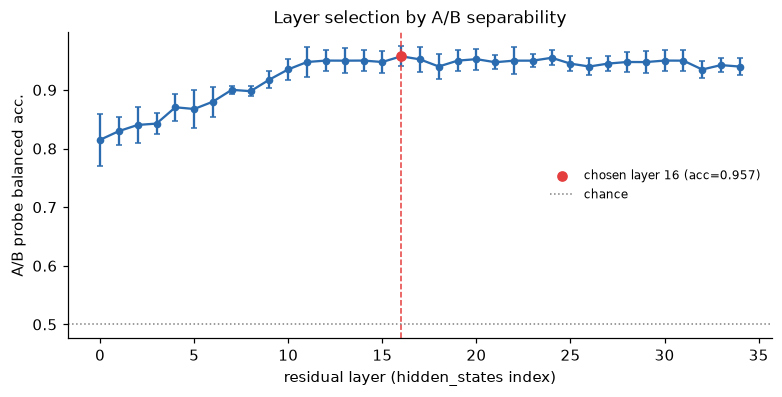

In [7]:
# equivalent to: scripts/01_extract_representations.py (layer-sweep half) +
# scripts/02_select_layer.py
# -> objects/layer_selection.json, objects/embeddings.npz, figures/01_layer_selection.*
from topolm import representations as R, layer_select as LS

if have(store, "layer_selection", "embeddings"):
    print("[cache] layer_selection/embeddings found on disk, loading")
    sel = store.load_json("layer_selection")
    if sel.get("per_layer"):
        sel["per_layer"] = {int(k): v for k, v in sel["per_layer"].items()}  # JSON keys are strings
    L = int(sel["best_layer"])
    emb = store.load_array("embeddings")
else:
    acts_all, idx = R.extract_all_layers(backend, texts, pooling=cfg.model.pooling,
                                         subsample=400, random_state=cfg.random_state)
    sel = LS.probe_separability_by_layer(acts_all, labels[idx], random_state=cfg.random_state)
    L = sel["best_layer"]
    emb = R.extract_layer(backend, texts, layer=L, pooling=cfg.model.pooling)
    store.save_json("layer_selection", sel)
    store.save_array("embeddings", emb, meta={"layer": int(L)})

print(f"chosen layer L={L}  (probe balanced acc={sel.get('best_acc')})")
fig = V.plot_layer_selection(sel) if sel.get("per_layer") else None
if fig is not None:
    show_fig(store, "01_layer_selection", fig)

n_topics=15


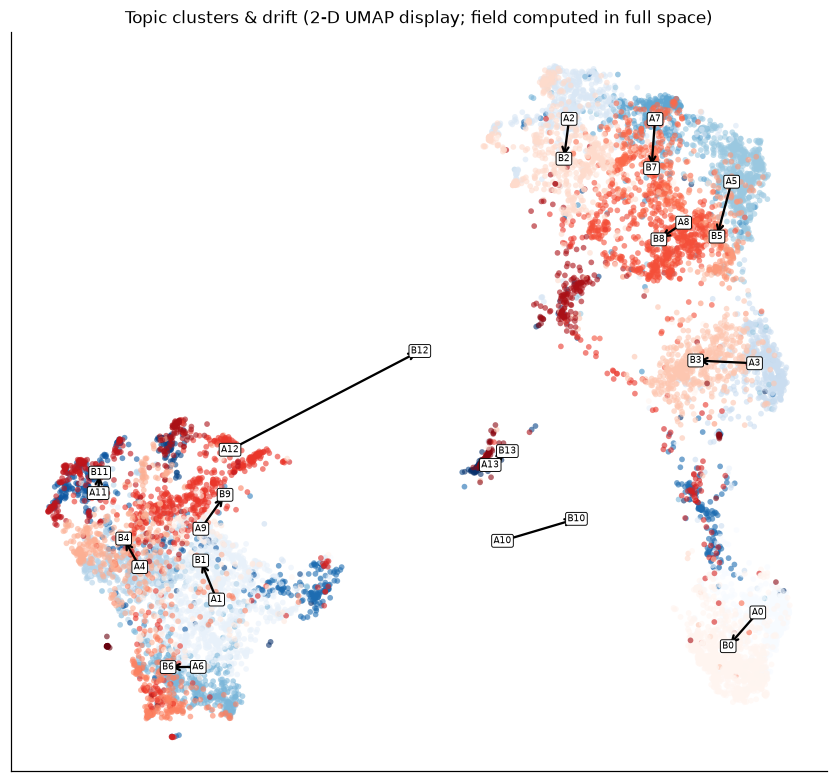

In [8]:
# equivalent to: scripts/03_cluster_manifold.py
# -> objects/cluster_labels.npz, objects/coords_2d.npz, figures/02_field_2d.*
if have(store, "cluster_labels", "coords_2d"):
    print("[cache] cluster_labels/coords_2d found on disk, loading")
    cluster_labels = store.load_array("cluster_labels").astype(int)
    coords_2d = store.load_array("coords_2d")
else:
    cl = M.cluster_documents(emb, cfg)
    cluster_labels = cl["labels"]
    coords_2d = cl["coords_2d"]
    store.save_array("cluster_labels", cluster_labels)
    store.save_array("coords_2d", coords_2d)

print(f"n_topics={len(np.unique(cluster_labels))}")
fig = V.plot_field_2d(coords_2d, cluster_labels, labels)
show_fig(store, "02_field_2d", fig)

In [9]:
# equivalent to: scripts/04_reconstruct_field.py
# -> objects/field.pkl
if have(store, "field"):
    print("[cache] field found on disk, loading")
    fld = store.load_object("field")
else:
    fld = F.reconstruct_field(emb, cluster_labels, labels)
    store.save_object("field", fld)

fs = F.field_stats(fld["V"])
print(f"topics with a CB vector: {len(fld['clusters'])}  |  m_bar={fs['m_bar']:.3f}  s_bar={fs['s_bar']:.3f}")

topics with a CB vector: 14  |  m_bar=370.878  s_bar=0.357


### Self-consistency check

`reconstruct_field` is a pure, deterministic function of `(emb, cluster_labels,
labels)`. Recomputing it fresh here and comparing against what this
notebook's own previous cell just saved as `"field"` is a cheap, live proof
that nothing in between perturbed it -- the CB vector this notebook reports
in Part 6 is exactly this function's output, nothing more.

In [10]:
fld_fresh = F.reconstruct_field(emb, cluster_labels, labels)
assert np.array_equal(fld_fresh["clusters"], fld["clusters"])
assert np.allclose(fld_fresh["V"], fld["V"])
print("self-consistency check passed: reconstruct_field(emb, cluster_labels, labels) "
      "is deterministic and matches the stored 'field' object exactly.")

self-consistency check passed: reconstruct_field(emb, cluster_labels, labels) is deterministic and matches the stored 'field' object exactly.


## 3 - Activation caching

*Script equivalent: `05_topol_cache_activations.py`. Saves to:
`objects/topol_acts_L{layer}.npz` (one float16 array per cached layer) +
`objects/topol_acts_meta.json` (which layers, how many tokens excluded).*

Cache mean-pooled residual activations at every layer discovery needs
(subject to `discovery.layer_stride`), EXCLUDING BOS and any special/
chat-template token positions from the pool. This matters because those
positions carry disproportionately large activation norms that would
otherwise dominate a topic's document centroid -- and it is a SEPARATE code
path from Part 2's `embed`/`embed_all_layers` (which pools over the FULL
attention mask), so nothing in Part 2 is affected by this choice.

The layer Part 2 chose (`L`) is always force-included in the cache,
regardless of `layer_stride`, so `discovery.ref_layer`'s default (Part 5) is
guaranteed to be available.

In [11]:
# P.step_topol_cache_activations -> topolm/topol_activations.py
if have(store, "topol_acts_meta"):
    print("[cache] topol activation cache found on disk, loading")
    cache = TA.load_activation_cache(store)
else:
    cache = P.step_topol_cache_activations(store, cfg, backend)

print(f"cached layers: {cache['layers']}")
excl = cache["excluded"]
print(f"excluded {excl['total_excluded_tokens']}/{excl['total_tokens']} pooled-token "
      f"positions ({excl['fraction_excluded']:.2%}) as BOS/special/chat-template")

[topol_activations] cached 18 layers (stride=2) for 9986 docs | excluded 9986/962467 (1.04%) pooled-token positions as BOS/special/chat-template
cached layers: [0, 2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24, 26, 28, 30, 32, 34]
excluded 9986/962467 pooled-token positions (1.04%) as BOS/special/chat-template


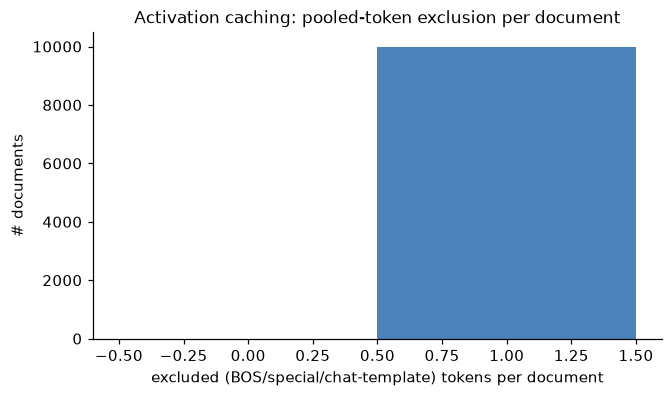

In [12]:
# -> figures/15_activation_exclusion.*
fig = V.plot_activation_exclusion(np.asarray(cache["excluded"]["per_doc_excluded"]))
show_fig(store, "15_activation_exclusion", fig)

## 4 - Per-topic discovery + the split-half gate

*Script equivalent: `06_topol_discovery.py`. Saves to:
`objects/topol_gate_results.pkl` (the full per-topic, per-contrast result),
`tables/topol_axis_summary.csv`, `tables/topol_rejected_preview.csv`.*

For every topic (from `cluster_labels`, unchanged): centre its documents on
their own mean at each cached layer, split with cosine 2-means, record the
partition, project the split direction out, and repeat up to
`discovery.max_depth` times (`topol_axes.recursive_bipartition`) -- stopping
early if a split's smaller side falls below `discovery.min_cluster_size`.
Every layer's candidates are then deduplicated by adjusted Rand index
(`topol_axes.dedup_candidates`) into contrasts, each given a full depth
profile across every cached layer (`topol_axes.depth_profile`) with a peak
layer l*.

The ONE filter in this whole path (`topol_gate.gate_topic`): split the
topic's documents into two disjoint halves, repeat everything above
independently on each half, and match the two halves' contrasts by \|cos\| at
l*. A contrast is only reported as passing if a matched half-pair reaches
\|cos\| >= `discovery.stability_threshold`.

This is the most expensive CPU step in the notebook (it reruns discovery
three times per topic: once on the full topic, once on each half) -- cached
like everything else, so it only runs once.

**Continuous rating recovery.** `topol_gate.gate_topic`'s nuisance
diagnostics (below) attach `corr_rating` -- correlation of an axis's
projection with the review's star rating -- to every contrast, but only if
a `ratings` array is threaded through discovery. `data.recover_ratings`
reconstructs it from the prepared Amazon pickle (mirroring `load_dataset`'s
exact filter/balance sequence and verifying the row order against this
run's own `labels` before trusting it); the next cell calls it. Part 6 below
needs this to test sentiment alignment directly rather than assume it, so if
you are resuming a run computed before this existed, delete/recompute
`topol_gate_results` (and `topol_baseline_comparison`) to pick up real
`corr_rating` values instead of stale NaNs.

In [14]:
# P.step_topol_discovery -> topolm/topol_axes.py + topolm/topol_gate.py
# -> objects/topol_gate_results.pkl
if have(store, "topol_gate_results"):
    print("[cache] topol_gate_results found on disk, loading")
    gate_results = store.load_object("topol_gate_results")
else:
    gate_results = P.step_topol_discovery(store, cfg, cache=cache,
                                          cluster_labels=cluster_labels, texts=texts,
                                          ratings=ratings)

n_topics = len(gate_results)
n_cand = sum(len(r["contrasts"]) for r in gate_results.values())
n_pass = sum(sum(1 for c in r["contrasts"] if c["passed"]) for r in gate_results.values())
print(f"{n_topics} topics analysed | {n_pass}/{n_cand} contrasts passed the gate "
      f"(stability_threshold={cfg.discovery.stability_threshold})")

  topic 0: 1285 docs | 45/53 contrasts passed the gate (threshold=0.6)
  topic 1: 1095 docs | 35/49 contrasts passed the gate (threshold=0.6)
  topic 2: 1077 docs | 36/48 contrasts passed the gate (threshold=0.6)
  topic 3: 1049 docs | 40/47 contrasts passed the gate (threshold=0.6)
  topic 4: 831 docs | 42/57 contrasts passed the gate (threshold=0.6)
  topic 5: 830 docs | 43/51 contrasts passed the gate (threshold=0.6)
  topic 6: 705 docs | 41/50 contrasts passed the gate (threshold=0.6)
  topic 7: 612 docs | 36/49 contrasts passed the gate (threshold=0.6)
  topic 8: 585 docs | 40/53 contrasts passed the gate (threshold=0.6)
  topic 9: 557 docs | 43/56 contrasts passed the gate (threshold=0.6)
  topic 10: 408 docs | 35/49 contrasts passed the gate (threshold=0.6)
  topic 11: 376 docs | 33/51 contrasts passed the gate (threshold=0.6)
  topic 12: 341 docs | 37/52 contrasts passed the gate (threshold=0.6)
  topic 13: 220 docs | 37/54 contrasts passed the gate (threshold=0.6)
  topic 14: 

In [15]:
topic_summary = pd.DataFrame([
    {"topic": t, "n_docs": int((cluster_labels == t).sum()),
     "n_candidates": len(r["contrasts"]),
     "n_passed": sum(1 for c in r["contrasts"] if c["passed"])}
    for t, r in gate_results.items()
]).sort_values("topic").reset_index(drop=True)
display(topic_summary)

,topic,n_docs,n_candidates,n_passed
0,0,1285,53,45
1,1,1095,49,35
2,2,1077,48,36
3,3,1049,47,40
4,4,831,57,42
5,5,830,51,43
6,6,705,50,41
7,7,612,49,36
8,8,585,53,40
9,9,557,56,43


In [16]:
# -> tables/topol_axis_summary.csv (+ .parquet)
axis_rows = []
for t, r in gate_results.items():
    for ci, c in enumerate(r["contrasts"]):
        axis_rows.append({
            "topic": t, "contrast_index": ci, "passed": c["passed"],
            "found_layer": c["found_layer"], "found_depth": c["found_depth"],
            "layers_found": c["layers_found"], "l_star": c["l_star"],
            "effect_size_at_lstar": round(c["effect_size_at_lstar"], 4),
            "split_half_cos": None if c["split_half_cos"] is None else round(c["split_half_cos"], 4),
            "corr_length": round(c["corr_length"], 4) if pd.notna(c["corr_length"]) else None,
            "corr_rating": round(c["corr_rating"], 4) if pd.notna(c["corr_rating"]) else None,
            "r2_product_id": c["r2_product_id"],
        })
axis_summary = pd.DataFrame(axis_rows)
store.save_table("topol_axis_summary", axis_summary)
display(axis_summary)

,topic,contrast_index,passed,found_layer,found_depth,layers_found,l_star,effect_size_at_lstar,split_half_cos,corr_length,corr_rating,r2_product_id
0,0,0,False,2,2,[2],20,1.0963,NaN,-0.1137,None,NaN
1,0,1,True,8,3,[8],20,1.1477,0.9977,0.1087,None,NaN
2,0,2,True,4,3,[4],20,0.8707,0.9968,-0.1137,None,NaN
3,0,3,True,6,3,[6],20,1.0123,0.9958,0.1020,None,NaN
4,0,4,True,10,4,[10],20,1.0648,0.9581,-0.1196,None,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
714,13,49,True,10,2,[10],14,0.7637,0.9679,0.4410,None,NaN
715,13,50,True,4,1,[4],4,0.7942,0.9850,0.3822,None,NaN
716,13,51,True,2,3,[2],12,0.8303,0.9782,-0.4331,None,NaN
717,13,52,True,4,4,[4],12,0.7520,0.8814,0.4343,None,NaN


### Depth profiles for one example topic

d(l) at every cached layer for each candidate contrast in one topic (the
first topic with at least one gate-passing contrast), each marked at its own
l* -- the plot form of the `topol_axes.depth_profile` computation.

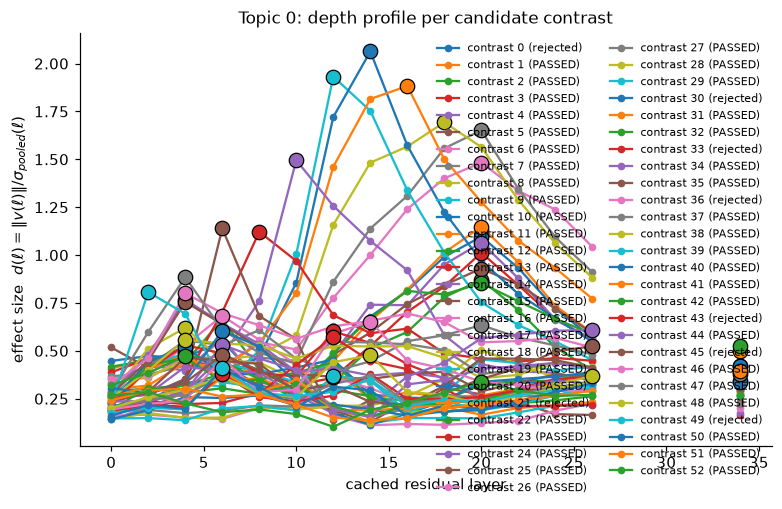

In [17]:
# -> figures/16_depth_profiles_example_topic.*
example_topic = next((t for t, r in gate_results.items() if any(c["passed"] for c in r["contrasts"])), None)
if example_topic is not None:
    ex_contrasts = gate_results[example_topic]["contrasts"]
    profiles = [
        {"label": f"contrast {ci} ({'PASSED' if c['passed'] else 'rejected'})",
         "layers": sorted(c["profile"].keys()),
         "d": [c["profile"][l]["d"] for l in sorted(c["profile"].keys())],
         "l_star": c["l_star"]}
        for ci, c in enumerate(ex_contrasts)
    ]
    fig = V.plot_depth_profiles(profiles, title=f"Topic {example_topic}: depth profile per candidate contrast")
    show_fig(store, "16_depth_profiles_example_topic", fig)
else:
    print("no topic has a gate-passing contrast to plot -- try lowering discovery.stability_threshold")

### Gate stability: the full split-half |cos| distribution

Every half-vs-half matched pair's \|cos\|, pooled across all topics, with
`stability_threshold` marked -- logged in full precisely so the default
(0.6) can be revisited empirically rather than trusted blindly.

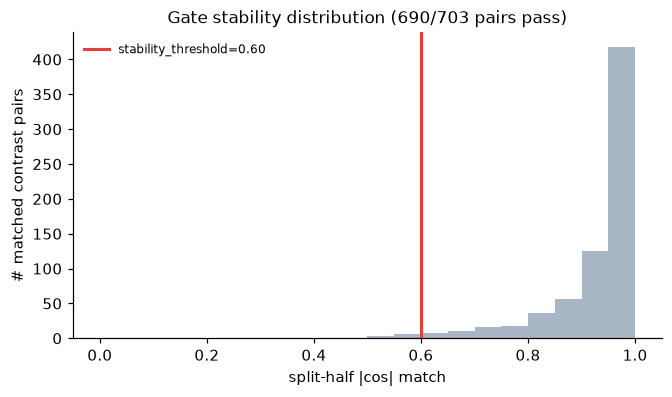

703 half-vs-half matched pairs pooled across all topics


In [18]:
# -> figures/17_gate_stability.*
all_match_cos = [cos for r in gate_results.values() for cos in r["match_cos_distribution"]]
fig = V.plot_gate_stability(all_match_cos, threshold=cfg.discovery.stability_threshold)
show_fig(store, "17_gate_stability", fig)
print(f"{len(all_match_cos)} half-vs-half matched pairs pooled across all topics")

In [19]:
# -> tables/topol_rejected_preview.csv (+ .parquet)
rejected_rows = [{"topic": t, **rej} for t, r in gate_results.items() for rej in r["rejected"]]
rejected_df = pd.DataFrame(rejected_rows)
store.save_table("topol_rejected_preview", rejected_df)
print(f"{len(rejected_df)} rejected split-half contrasts logged")
display(rejected_df.head(15))

62 rejected split-half contrasts logged


,topic,source,half1_index,cos,half2_index
0,0,half1_unmatched,28.0,NaN,NaN
1,0,half1_unmatched,29.0,NaN,NaN
2,0,half1_unmatched,35.0,NaN,NaN
3,0,half1_unmatched,41.0,NaN,NaN
4,1,half_pair,23.0,0.275749,48.0
5,1,half2_unmatched,NaN,NaN,27.0
6,2,half_pair,4.0,0.595017,41.0
7,2,half1_unmatched,17.0,NaN,NaN
8,2,half1_unmatched,23.0,NaN,NaN
9,3,half_pair,48.0,0.211270,40.0


### Nuisance diagnostics (recorded, never gated)

Three correlations are attached to every discovered contrast but NEVER used
to decide pass/fail: correlation of the axis's document projection with
review length, with star rating, and a one-way ANOVA R^2 with product id
(always NaN here -- the current Amazon corpus prep exposes no product
identifier; see `README_pipeline_2.md`). These are diagnostics for the next
iteration of this method, not a filter.

In [20]:
display(axis_summary[["topic", "contrast_index", "passed", "corr_length", "corr_rating", "r2_product_id"]])

,topic,contrast_index,passed,corr_length,corr_rating,r2_product_id
0,0,0,False,-0.1137,None,NaN
1,0,1,True,0.1087,None,NaN
2,0,2,True,-0.1137,None,NaN
3,0,3,True,0.1020,None,NaN
4,0,4,True,-0.1196,None,NaN
...,...,...,...,...,...,...
714,13,49,True,0.4410,None,NaN
715,13,50,True,0.3822,None,NaN
716,13,51,True,-0.4331,None,NaN
717,13,52,True,0.4343,None,NaN


## 5 - Cross-topic field assembly

*Script equivalent: `07_topol_field_assembly.py`. Saves to:
`objects/topol_field_summary.json`.*

Per topic: r_t = number of gate-passing contrasts (`field.topic_rank_estimate`)
-- NOT a participation ratio, because recursive projection makes a topic's
own discovered axes orthogonal by construction; the count IS the rank
estimate.

Across topics: pool every gate-passing axis, evaluated at the fixed
`discovery.ref_layer`, into ONE ensemble and compute its uncentred second
moment -- here PR IS meaningful, since axes discovered in different topics
are not constructed orthogonal to one another (`field.pooled_field_assembly`).
Also clusters the pooled axes into families by \|cos\| direction similarity
(`field.axis_families`).

**On the depth-profile clustering this cell used to also compute:** an
earlier version tried a second, "geometry-independent" family clustering by
correlating axes' depth profiles $d(\ell)$ instead of their raw direction.
It produced a degenerate result -- all 543 axes as singleton families,
chance-level agreement with the \|cos\|-based clustering -- because a
layer-by-layer effect-size curve is a poor proxy for what a direction is
about. It has been removed from `field.py` (see that module's docstring).
`pipeline_2_part2.ipynb`'s semantic-family-clustering section (after its
TF-IDF step, which this one needs as input) replaces it with a clustering
that actually answers "do these axes mean the same thing": each axis's own
differential TF-IDF vocabulary, not its geometry at all
(`topolm/axis_semantics.py`, script `14_semantic_family_clustering.py`).

In [21]:
# P.step_topol_field -> topolm/field.py (pooled_field_assembly, axis_families, topic_rank_estimate)
# -> objects/topol_field_summary.json
if have(store, "topol_field_summary"):
    print("[cache] topol_field_summary found on disk, loading")
else:
    P.step_topol_field(store, cfg, gate_results=gate_results, cache=cache)

# always read back from disk so dict keys are consistently strings whether
# this cell just computed the summary or loaded it from a previous run
field_summary = store.load_json("topol_field_summary")
ref_layer = field_summary["ref_layer"]

print(f"reference layer for pooling: {ref_layer}")
print(f"pooled k={field_summary['k']} gate-passing axes across {len(gate_results)} topics | "
      f"PR={field_summary['pr']:.3f}")

  pooled field: k=543 gate-passing axes across 14 topics | PR=1.184 @ layer 16
reference layer for pooling: 16
pooled k=543 gate-passing axes across 14 topics | PR=1.184


In [22]:
rank_df = pd.DataFrame([
    {"topic": int(t), "r_t": v["r_t"], "n_candidates": v["n_candidates"]}
    for t, v in field_summary["per_topic_rank"].items()
]).sort_values("topic").reset_index(drop=True)
display(rank_df)

,topic,r_t,n_candidates
0,0,45,53
1,1,35,49
2,2,36,48
3,3,40,47
4,4,42,57
5,5,43,51
6,6,41,50
7,7,36,49
8,8,40,53
9,9,43,56


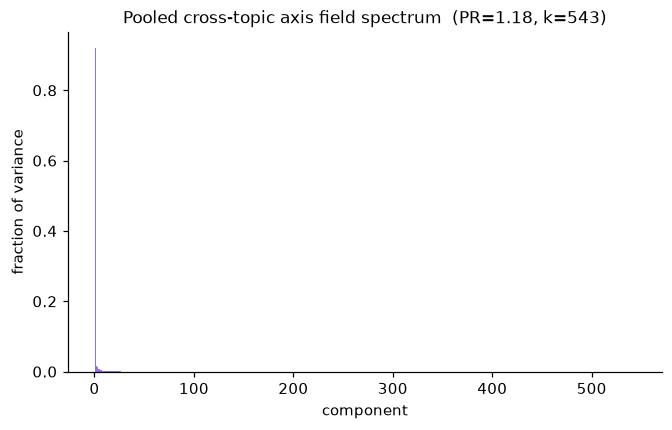

In [23]:
# -> figures/18_pooled_spectrum.*
fig = V.plot_pooled_spectrum(field_summary["spectrum"], field_summary["pr"])
show_fig(store, "18_pooled_spectrum", fig)

### The pooled field of discovered axes, as vectors

The same two views the CB field uses for its per-topic vectors
(`viz.plot_vector_relations`/`plot_vector_compass`), reused here on the
pooled, cross-topic ensemble of gate-passing discovered axes instead --
these two plotting functions only need a `(k, d)` matrix of vectors and don't
care what object each row represents.

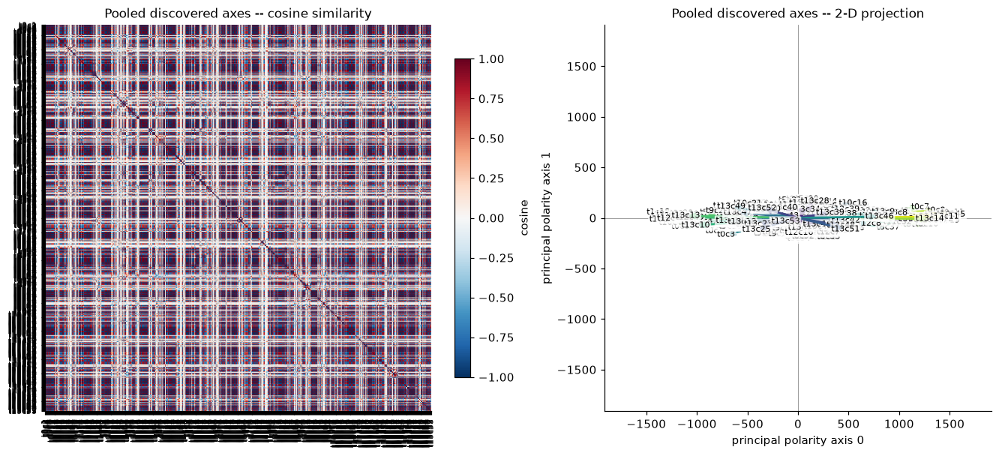

In [24]:
# -> figures/19_pooled_field_of_axes.*
from topolm import dimensionality as DIM

pooled = F.pooled_field_assembly(gate_results, ref_layer, cache["layers"])
axis_ids_pooled = [f"t{t}c{c}" for t, c in zip(pooled["topic_ids"], pooled["contrast_ids"])]

if pooled["k"] >= 2:
    axes2d, _ = DIM.principal_axes(pooled["V"], n_axes=2, center=False)
    fig, axs = plt.subplots(1, 2, figsize=(12, 5.5), layout="constrained")
    V.plot_vector_relations(pooled["V"], axis_ids_pooled, ax=axs[0],
                            title="Pooled discovered axes -- cosine similarity")
    V.plot_vector_compass(pooled["V"], axis_ids_pooled, axes2d, ax=axs[1],
                          title="Pooled discovered axes -- 2-D projection")
    show_fig(store, "19_pooled_field_of_axes", fig)
else:
    print(f"only {pooled['k']} gate-passing axis(es) survived -- need >= 2 to plot relations/compass")

In [46]:
# -> tables/topol_pooled_axis_vectors.csv, tables/topol_pooled_axis_pairwise.csv
# -> objects/topol_pooled_axis_geometry.npz
#
# Persists the exact geometry behind the `d863838f` compass/relations plot:
# per-vector table (topic, own discovered layer, magnitude, 2-D projection)
# and a pairwise table (cosine similarity / angle / Euclidean distance
# between every pair of pooled axes) -- the raw numbers the two panels of
# `19_pooled_field_of_axes` are drawn from, since neither plot saves them.

assert pooled["k"] >= 2, "need >= 2 pooled axes (see the `d863838f` cell above) before this cell"

V_full = pooled["V"]                              # (k, d) -- each row at `ref_layer`
proj_2d = V_full @ axes2d.T                        # (k, 2) -- same projection plot_vector_compass uses
magnitude_full = np.linalg.norm(V_full, axis=1)
magnitude_2d = np.linalg.norm(proj_2d, axis=1)
angle_2d_deg = np.degrees(np.arctan2(proj_2d[:, 1], proj_2d[:, 0]))

# each pooled row's OWN discovered layer (l*), vs. the single `ref_layer`
# every row above is evaluated at for cross-topic comparability -- these can
# differ, which is itself worth having on hand.
per_vector_rows = []
for i, (t, ci) in enumerate(zip(pooled["topic_ids"], pooled["contrast_ids"])):
    c = gate_results[t]["contrasts"][ci]
    per_vector_rows.append({
        "axis_id": axis_ids_pooled[i], "topic": int(t), "contrast_index": int(ci),
        "l_star": c["l_star"], "found_layer": c["found_layer"], "found_depth": c["found_depth"],
        "ref_layer": int(ref_layer),
        "effect_size_at_lstar": round(float(c["effect_size_at_lstar"]), 4),
        "split_half_cos": None if c["split_half_cos"] is None else round(float(c["split_half_cos"]), 4),
        "magnitude_full": round(float(magnitude_full[i]), 4),
        "magnitude_2d": round(float(magnitude_2d[i]), 4),
        "proj_x": round(float(proj_2d[i, 0]), 4), "proj_y": round(float(proj_2d[i, 1]), 4),
        "angle_2d_deg": round(float(angle_2d_deg[i]), 2),
    })
pooled_vector_df = pd.DataFrame(per_vector_rows)
store.save_table("topol_pooled_axis_vectors", pooled_vector_df)
display(pooled_vector_df)

# pairwise relations: direction (cosine, angle) and distance (Euclidean, in
# both the full d-dim space and the 2-D projection) between every pair --
# long form, upper triangle only, so it merges/filters cleanly.
Vn = V_full / (magnitude_full[:, None] + 1e-12)
cos_mat = np.clip(Vn @ Vn.T, -1.0, 1.0)
eucl_full_mat = np.linalg.norm(V_full[:, None, :] - V_full[None, :, :], axis=-1)
eucl_2d_mat = np.linalg.norm(proj_2d[:, None, :] - proj_2d[None, :, :], axis=-1)

k = pooled["k"]
iu, ju = np.triu_indices(k, k=1)
pairwise_df = pd.DataFrame({
    "axis_id_i": [axis_ids_pooled[i] for i in iu], "axis_id_j": [axis_ids_pooled[j] for j in ju],
    "topic_i": [int(pooled["topic_ids"][i]) for i in iu], "topic_j": [int(pooled["topic_ids"][j]) for j in ju],
    "same_topic": [pooled["topic_ids"][i] == pooled["topic_ids"][j] for i, j in zip(iu, ju)],
    "cosine_similarity": cos_mat[iu, ju].round(4),
    "angle_deg_full": np.degrees(np.arccos(cos_mat[iu, ju])).round(2),
    "euclidean_distance_full": eucl_full_mat[iu, ju].round(4),
    "euclidean_distance_2d": eucl_2d_mat[iu, ju].round(4),
})
store.save_table("topol_pooled_axis_pairwise", pairwise_df)
display(pairwise_df)

# raw arrays for reuse without recomputation (full-dim vectors, 2-D
# projection, and both square distance/similarity matrices).
np.savez_compressed(
    os.path.join(store.objects, "topol_pooled_axis_geometry.npz"),
    V=V_full.astype(np.float32), proj_2d=proj_2d.astype(np.float32),
    cosine_matrix=cos_mat.astype(np.float32),
    euclidean_full_matrix=eucl_full_mat.astype(np.float32),
    euclidean_2d_matrix=eucl_2d_mat.astype(np.float32),
    axis_ids=np.array(axis_ids_pooled), topic_ids=np.array(pooled["topic_ids"]),
)
store._register("topol_pooled_axis_geometry", "array",
                os.path.join(store.objects, "topol_pooled_axis_geometry.npz"),
                {"shape": list(V_full.shape)})

# quick check on "direction should relate to meaning": are same-topic axis
# pairs more aligned in direction than cross-topic pairs?
print("mean |cosine|, same-topic pairs   :", pairwise_df.loc[pairwise_df.same_topic, "cosine_similarity"].abs().mean().round(4))
print("mean |cosine|, cross-topic pairs  :", pairwise_df.loc[~pairwise_df.same_topic, "cosine_similarity"].abs().mean().round(4))


,axis_id,topic,contrast_index,l_star,found_layer,found_depth,ref_layer,effect_size_at_lstar,split_half_cos,magnitude_full,magnitude_2d,proj_x,proj_y,angle_2d_deg
0,t0c1,0,1,20,8,3,16,1.1477,0.9977,841.2691,837.2772,-826.9667,-130.9930,-171.00
1,t0c2,0,2,20,4,3,16,0.8707,0.9968,635.8877,628.4347,623.4720,78.8215,7.21
2,t0c3,0,3,20,6,3,16,1.0123,0.9958,735.5292,730.6568,-711.6337,-165.6406,-166.90
3,t0c4,0,4,20,10,4,16,1.0648,0.9581,767.8779,757.5612,756.0359,48.0498,3.64
4,t0c5,0,5,20,0,1,16,0.9295,0.9978,773.4720,769.0214,765.5948,72.5161,5.41
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
538,t13c49,13,49,14,10,2,16,0.7637,0.9679,677.9688,669.5503,-660.2043,111.4802,170.42
539,t13c50,13,50,4,4,1,16,0.7942,0.9850,342.6581,324.0074,-312.3459,86.1443,164.58
540,t13c51,13,51,12,2,3,16,0.8303,0.9782,496.5826,483.0906,469.6939,-112.9788,-13.52
541,t13c52,13,52,12,4,4,16,0.7520,0.8814,380.6379,365.4109,-352.8058,95.1481,164.91


,axis_id_i,axis_id_j,topic_i,topic_j,same_topic,cosine_similarity,angle_deg_full,euclidean_distance_full,euclidean_distance_2d
0,t0c1,t0c2,0,0,True,-0.9951,174.34,1475.3931,1465.5356
1,t0c1,t0c3,0,0,True,0.9961,5.04,126.3744,120.4249
2,t0c1,t0c4,0,0,True,-0.9861,170.42,1603.5421,1593.0956
3,t0c1,t0c5,0,0,True,-0.9947,174.08,1612.5895,1605.5118
4,t0c1,t0c6,0,0,True,0.9919,7.28,353.0768,339.8277
...,...,...,...,...,...,...,...,...,...
147148,t13c50,t13c52,13,13,True,0.9091,24.62,158.5859,41.4497
147149,t13c50,t13c53,13,13,True,0.4855,60.96,299.5657,226.4905
147150,t13c51,t13c52,13,13,True,-0.9592,163.57,868.3779,848.4236
147151,t13c51,t13c53,13,13,True,-0.6141,127.89,613.3157,596.1605


mean |cosine|, same-topic pairs   : 0.5864
mean |cosine|, cross-topic pairs  : 0.5609


In [25]:
families = field_summary["families"]
print(f"families by |cos| direction: {len(families.get('families_by_cos', {}))}")

fam_cos_df = pd.DataFrame([{"family": k, "topics": v} for k, v in families.get("families_by_cos", {}).items()])
print("\nfamilies by |cos| direction:")
display(fam_cos_df)

families by |cos| direction: 90

families by |cos| direction:


,family,topics
0,84,"[0, 1, 10, 11, 12, 13, 2, 3, 4, 5, 6, 7, 8, 9]"
1,63,"[0, 2, 5, 7]"
2,78,"[0, 11, 13, 3, 4, 5]"
3,12,"[0, 3, 8]"
4,64,"[0, 1, 12, 6, 8]"
...,...,...
85,34,[12]
86,20,[13]
87,45,[13]
88,28,[13]


## 6 - Comparison against the CB polarity vector

*Script equivalent: `08_topol_baseline_compare.py`. Saves to:
`objects/topol_baseline_comparison.json`, `objects/topol_cb_axis_report.json`.*

Per topic: compute $v_{CB}^t$'s OWN depth profile and peak layer, by the same
procedure used for discovered axes (`topol_axes.depth_profile` on the
original CB regime labels, not a discovered partition), then report:

* **identification** -- max_j \|cos(a_j, v_CB^t)\| at `ref_layer`, and which
  gate-passing axis achieves it: is $v_{CB}^t$ represented among the
  discovered axes at all.
* **sentiment alignment** -- `cb_corr_rating`: Pearson correlation between
  $v_{CB}^t$'s OWN projection and the CONTINUOUS star rating (not the
  two-class label used to build $v_{CB}^t$ itself -- correlating against
  that would be circular). This is the actual, measured test of "is the
  human-coded CB sentiment aligned". Every OTHER gate-passing axis already
  carries the same correlation (`corr_rating`, Part 4's nuisance
  diagnostics); `most_sentiment_aligned_index` is whichever passing axis has
  the largest \|corr_rating\|. `step_topol_baseline_compare` prints a WARNING
  if $v_{CB}^t$'s own correlation is weak (below
  `discovery.sentiment_corr_threshold`), and a NOTE if the axis identified by
  cosine similarity is NOT the most sentiment-aligned one.

  **This replaces an earlier, dropped assumption** that identification
  should always land at a topic's first recursion depth (reasoning:
  dropping the middle band should make sentiment dominate the topic cloud's
  variance). That did not hold up empirically -- recursion depth is an
  artifact of how much OTHER structure got deflated out first, not a
  measure of sentiment alignment -- so it is no longer asserted or warned
  on; sentiment alignment is now measured directly against the continuous
  rating instead.
* **excess structure** -- count of gate-passing axes with \|cos\| below
  `discovery.excess_cos_threshold` to $v_{CB}^t$: the additional, independent
  dimensions the opening question above asks about.
* **layer agreement** -- $l^*$ of the CB-matched axis vs $l^*$ of the excess
  axes: the direct test of whether "extra" structure lives at a different
  depth than sentiment.

If Part 4's rating recovery returned `None` (a non-Amazon dataset, or a
cached `topol_gate_results` computed before rating recovery existed),
`cb_corr_rating` and every sentiment-alignment field below are NaN/`None`;
identification, excess structure and layer agreement are unaffected.

In [26]:
# P.step_topol_baseline_compare -> topolm/pipeline.py + topolm/topol_axes.py + topolm/topol_report.py
# -> objects/topol_baseline_comparison.json, objects/topol_cb_axis_report.json
if have(store, "topol_baseline_comparison", "topol_cb_axis_report"):
    print("[cache] topol_baseline_comparison found on disk, loading")
else:
    P.step_topol_baseline_compare(store, cfg, gate_results=gate_results, cache=cache,
                                  cluster_labels=cluster_labels, ratings=ratings, texts=texts)

baseline_cmp = store.load_json("topol_baseline_comparison")
baseline_df = pd.DataFrame(
    [{"topic": int(t), **v} for t, v in baseline_cmp.items()]
).sort_values("topic").reset_index(drop=True)
display(baseline_df[["topic", "cb_l_star", "cb_corr_rating", "identification_cos",
                     "identification_l_star", "identification_corr_rating",
                     "most_sentiment_aligned_index", "most_sentiment_aligned_abs_corr_rating",
                     "identification_matches_most_sentiment_aligned",
                     "excess_count", "n_passing"]])

,topic,cb_l_star,cb_corr_rating,identification_cos,identification_l_star,identification_corr_rating,most_sentiment_aligned_index,most_sentiment_aligned_abs_corr_rating,identification_matches_most_sentiment_aligned,excess_count,n_passing
0,0,34,NaN,0.811560,20,NaN,None,NaN,None,8,45
1,1,34,NaN,0.813422,16,NaN,None,NaN,None,4,35
2,2,14,NaN,0.929337,24,NaN,None,NaN,None,9,36
3,3,26,NaN,0.972787,20,NaN,None,NaN,None,8,40
4,4,20,NaN,0.952897,22,NaN,None,NaN,None,7,42
5,5,22,NaN,0.854241,20,NaN,None,NaN,None,14,43
6,6,22,NaN,0.884586,34,NaN,None,NaN,None,6,41
7,7,34,NaN,0.823319,34,NaN,None,NaN,None,16,36
8,8,18,NaN,0.705543,20,NaN,None,NaN,None,5,40
9,9,14,NaN,0.837749,14,NaN,None,NaN,None,7,43


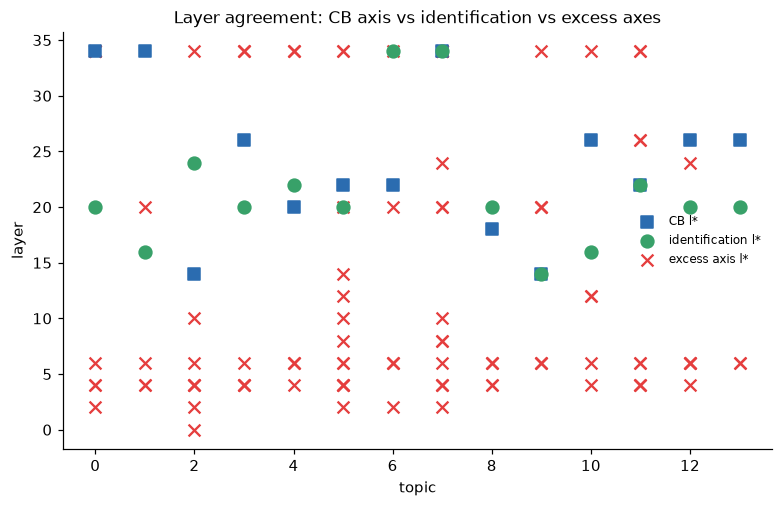

In [27]:
# -> figures/20_baseline_layer_agreement.*
fig = V.plot_baseline_layer_agreement(baseline_df)
show_fig(store, "20_baseline_layer_agreement", fig)

### Sentiment alignment: v_CB vs. identification vs. every passing axis

Per topic: \|corr(projection, rating)\| for $v_{CB}^t$ itself (blue square),
the axis matched by cosine similarity to $v_{CB}^t$ (green circle if it is
ALSO the most sentiment-aligned axis, red if some other axis tracks rating
better), and every other gate-passing axis (grey dots) -- the plotted form
of the measured checks Part 6's markdown describes, in place of the dropped
recursion-depth assumption.

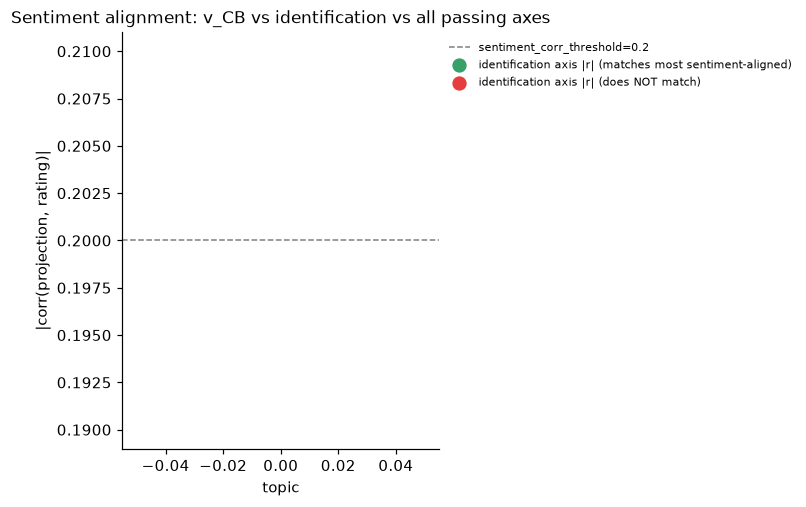

In [28]:
# -> figures/20b_sentiment_alignment.*
fig = V.plot_sentiment_alignment(baseline_df, sentiment_corr_threshold=cfg.discovery.sentiment_corr_threshold)
show_fig(store, "20b_sentiment_alignment", fig)

### Reading v_CB^t itself: highest/lowest-projecting reviews per topic

The qualitative half of "is the CB axis sentiment aligned": `cb_axis_report`
(saved as `topol_cb_axis_report.json` when `texts` is passed to
`step_topol_baseline_compare`) records the highest- and lowest-projecting
reviews along $v_{CB}^t$ for every topic -- if $v_{CB}^t$ is really the
sentiment axis, its high pole should read as clearly positive and its low
pole as clearly negative, the same "read twenty reviews" check
`topol_report.py` already applies to discovered axes (Part 7 below).

In [29]:
cb_reports = store.load_json("topol_cb_axis_report") if have(store, "topol_cb_axis_report") else {}


def print_cb_axis_texts(topic, n=5):
    rec = cb_reports.get(str(topic))
    if rec is None:
        print(f"no CB axis report for topic {topic}")
        return
    print(f"topic {topic} | v_CB l*={rec['l_star']} | corr_rating={rec['corr_rating']:.3f}\n")
    print(f"-- HIGH pole (top {n}) --")
    for d in rec["pole_high_texts"][:n]:
        print(f"  [{d['projection']:+.2f}] {d['text'][:200]}")
    print(f"\n-- LOW pole (top {n}) --")
    for d in rec["pole_low_texts"][:n]:
        print(f"  [{d['projection']:+.2f}] {d['text'][:200]}")


if cb_reports:
    print_cb_axis_texts(int(baseline_df["topic"].iloc[0]), n=5)
else:
    print("no topol_cb_axis_report found -- Part 6 must be (re)run with `texts` passed in")

topic 0 | v_CB l*=34 | corr_rating=nan

-- HIGH pole (top 5) --
  [+21.10] Love in All Its Colors This CD features the extraordinary voice of Christine Andreas,now featured on Broadway in "The Scarlet Pimpernel". Technique and passion blend into a very pleasing menu of songs
  [+20.92] More Wonderful Motown Music ! Motown magic continues on this great CD ! Particular favorite is You've Got To Pay The Price by The Supremes. A DATE track with Jean Terell doing the lead.
  [+20.81] TRACK LIST Track Listings1. Latino Suite2. Lil' Darlin'NUM. Dreamer4. Satin Doll5. Down Home6. Sudan7. Lover Man8. Rhythm-A-Ning
  [+19.32] Perfection! An album and DVD from this wonderful performer. A longawaited follow up to the "Generations" album,but far superior. A more sophisticated sound thenanything Mr. Jason has released before. 
  [+18.76] Awesome blend of Genres... Fantastic fusion of bluegrass, celtic and Americana. Some outstanding music here - Lordy, Lordy, Seven Story Mountain, Chains, Railroad E

## 7 - Reporting: text extremes + rejected log

*Script equivalent: `08_topol_baseline_compare.py` (same script also builds
this report). Saves to: `objects/topol_report_full.json`,
`tables/topol_report_summary.csv`, `tables/topol_report_rejected.csv`.*

For every gate-passing axis: topic, l*, the layers that found it, effect
size at l*, split-half \|cos\|, the three nuisance diagnostics, and the 10
highest- and 10 lowest-projecting review texts on each pole
(`topol_report.build_report`). This is the interpretation route -- no SAE,
no LLM narration, just the documents: if an axis is real and semantic,
reading twenty reviews should show it.

In [30]:
if have(store, "topol_report_full"):
    print("[cache] topol_report_full found on disk, loading")
    report = store.load_json("topol_report_full")
else:
    report = TR.build_report(gate_results, texts, cluster_labels, cache, n_extreme=10)
    TR.save_report(store, report)

print(f"{len(report['axes'])} surviving axes reported | {len(report['rejected'])} rejected contrasts logged")
report_summary = load_table(store, "topol_report_summary")
display(report_summary)

543 surviving axes reported | 62 rejected contrasts logged


,topic,contrast_index,l_star,found_layer,found_depth,layers_found,effect_size_at_lstar,split_half_cos,corr_length,corr_rating,r2_product_id
0,0,1,20,8,3,8,1.147746,0.997728,0.108680,NaN,NaN
1,0,2,20,4,3,4,0.870738,0.996825,-0.113654,NaN,NaN
2,0,3,20,6,3,6,1.012284,0.995826,0.101979,NaN,NaN
3,0,4,20,10,4,10,1.064766,0.958059,-0.119555,NaN,NaN
4,0,5,20,0,1,0,0.929510,0.997834,-0.113202,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
538,13,49,14,10,2,10,0.763717,0.967918,0.440952,NaN,NaN
539,13,50,4,4,1,4,0.794173,0.985009,0.382160,NaN,NaN
540,13,51,12,2,3,2,0.830279,0.978199,-0.433088,NaN,NaN
541,13,52,12,4,4,4,0.751999,0.881389,0.434312,NaN,NaN


### Reading an axis: the 10 highest/lowest-projecting reviews on each pole

In [31]:
def print_axis_texts(report, topic, contrast_index, n=5):
    rec = next((a for a in report["axes"]
               if a["topic"] == topic and a["contrast_index"] == contrast_index), None)
    if rec is None:
        print(f"no surviving axis at topic={topic}, contrast_index={contrast_index}")
        return
    print(f"topic {topic}, contrast {contrast_index}  |  l*={rec['l_star']}  "
          f"effect_size={rec['effect_size_at_lstar']:.3f}  "
          f"split_half_cos={rec['split_half_cos']:.3f}")
    print("\n-- highest-projecting pole --")
    for r in rec["pole_high_texts"][:n]:
        print(f"  [{r['projection']:+.2f}] {r['text'][:200]}")
    print("\n-- lowest-projecting pole --")
    for r in rec["pole_low_texts"][:n]:
        print(f"  [{r['projection']:+.2f}] {r['text'][:200]}")


# worked example: the surviving axis with the largest effect size at its own l*
if report["axes"]:
    example = max(report["axes"], key=lambda a: a["effect_size_at_lstar"])
    print_axis_texts(report, example["topic"], example["contrast_index"])
else:
    print("no surviving axes to show -- try lowering discovery.stability_threshold")

topic 13, contrast 14  |  l*=14  effect_size=2.340  split_half_cos=0.998

-- highest-projecting pole --
  [+1710.26] Great Game, Mediocre Expansion Dawn of War is a great game, but this expansion was so-so. Campaign was pretty good, but the Imperial Guard (the additional race in this expansion) is a lame race in my 
  [+1693.98] Stay away! Doesn't work on XP, joystick is too sensitive, overall the worst excuse for a flight sim.
  [+1459.11] Successful Portable Strategy I was both pleased and intrigued to hear that Age of Empires could be played on the Nintendo DS. The turn based combat works well, the graphics are pleasing, though simple
  [+1456.20] Hopefully best game ever! Civ3 seems to be expanding the possibilities of previous Civ games. Diplomacy and trade will be in bigger role, characteristics of different races will be great new addition 
  [+1329.49] Crackdown While I did enjoy playing this game the first time around, I found to my sheer and utter disappointment that I cannot

In [32]:
rejected_full_df = pd.DataFrame(report["rejected"])
print(f"{len(rejected_full_df)} rejected contrasts total (full log saved as topol_report_rejected)")
display(rejected_full_df.head(20))

62 rejected contrasts total (full log saved as topol_report_rejected)


,topic,source,half1_index,cos,half2_index
0,0,half1_unmatched,28.0,NaN,NaN
1,0,half1_unmatched,29.0,NaN,NaN
2,0,half1_unmatched,35.0,NaN,NaN
3,0,half1_unmatched,41.0,NaN,NaN
4,1,half_pair,23.0,0.275749,48.0
5,1,half2_unmatched,NaN,NaN,27.0
6,2,half_pair,4.0,0.595017,41.0
7,2,half1_unmatched,17.0,NaN,NaN
8,2,half1_unmatched,23.0,NaN,NaN
9,3,half_pair,48.0,0.211270,40.0


## 8 - NLA: what does each discovered polar vector mean, in words?

*Notebook-only -- no standalone script yet. Saves to: `objects/topol_nla_*`
(vocab, encoder, decoder, training history, AR results) and
`tables/topol_nla_*` (axis index, pole contrast, prototypes, direction sweep,
direction summary).*

A small VAE-style bottleneck (`activation -> 256-d embedding -> description
tokens`, `topolm/nla.py`) trained on every gate-passing discovered axis, each
read at **its own discovered layer l\*, not one shared layer** --
`nla.py`'s encoder/decoder support a per-document, non-constant `layer_id`
for exactly this (`prepare_dataset`'s docstring anticipates it: "kept as a
real input so a future joint-dataset run has somewhere to put a non-constant
layer id"). `nla.prepare_axis_dataset` is that joint-dataset run.

For every gate-passing axis (topic, contrast): its own topic's documents, its
own activation at l\*, and its OWN discovered partition as the pole label
(**not** the corpus's CB regime label -- this interrogates a DISCOVERED axis,
not the CB one). Each axis becomes its own "axis id" in NLA's topic-
conditioning embedding, so ONE trained model serves every axis, in every
topic, at each axis's correct layer -- `axis_index` carries both the
original `topic` and the `axis_id`, so every table below can be read either
"per topic" (group by `topic`) or "across topics" (the ungrouped table).

In [33]:
# NLA.build_vocab -> topolm/nla.py
# -> objects/topol_nla_vocab.pkl
assert have(store, "topol_gate_results"), (
    "Run Part 4 (discovery + gate) first -- NLA interrogation needs gate_results.")

if have(store, "topol_nla_vocab"):
    print("[cache] topol_nla_vocab found on disk, loading")
    vocab = store.load_object("topol_nla_vocab")
else:
    vocab = NLA.build_vocab(texts, max_size=4000)
    store.save_object("topol_nla_vocab", vocab)

print("vocab size:", len(vocab))

vocab size: 4004


In [34]:
# NLA.prepare_axis_dataset -> topolm/nla.py
# -> tables/topol_nla_axis_index.csv
data, axis_index = NLA.prepare_axis_dataset(gate_results, texts, cluster_labels, cache, vocab, max_len=48)
store.save_table("topol_nla_axis_index", axis_index)

print(f"pooled NLA dataset: {data['activations'].shape[0]} rows across {data['n_topics']} axes, "
      f"{len(data['layers_used'])} distinct layers used: {data['layers_used']}")
display(axis_index)

pooled NLA dataset: 393207 rows across 543 axes, 15 distinct layers used: [0, 2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24, 26, 34]


,axis_id,topic,contrast_index,l_star,layer_id,effect_size_at_lstar,split_half_cos,n_docs
0,0,0,1,20,10,1.147746,0.997728,1285
1,1,0,2,20,10,0.870738,0.996825,1285
2,2,0,3,20,10,1.012284,0.995826,1285
3,3,0,4,20,10,1.064766,0.958059,1285
4,4,0,5,20,10,0.929510,0.997834,1285
...,...,...,...,...,...,...,...,...
538,538,13,49,14,7,0.763717,0.967918,220
539,539,13,50,4,2,0.794173,0.985009,220
540,540,13,51,12,6,0.830279,0.978199,220
541,541,13,52,12,6,0.751999,0.881389,220


### Train NLA (STAGE 2) + AR (STAGE 3)

`NLAEncoder`/`NLADecoder` (CE reconstruction of each document's own
truncated text + KL regularisation), then a SEPARATE `ARHead` regression
from the frozen NLA embedding back to the real activation, evaluated under
5-fold cross-validation. Runs on `device="cuda"` by default -- set
`device="cpu"` if no GPU is available; a pooled dataset this size still
trains in well under a few minutes on CPU.

In [ ]:
# NLA.train_nla -> topolm/nla.py
# -> objects/topol_nla_encoder.pkl, topol_nla_decoder.pkl, topol_nla_history.pkl
if have(store, "topol_nla_encoder", "topol_nla_decoder", "topol_nla_history"):
    print("[cache] topol_nla_encoder/decoder found on disk, loading")
    nla_result = {"encoder": store.load_object("topol_nla_encoder"),
                 "decoder": store.load_object("topol_nla_decoder"),
                 "history": store.load_object("topol_nla_history"),
                 "latent_dim": 256, "n_topics": data["n_topics"],
                 "n_layers": int(data["layer_ids"].max()) + 1}
else:
    nla_result = NLA.train_nla(data, vocab, latent_dim=256, hidden_dim=512,
                               epochs=3, device="cuda", random_state=42)
    store.save_object("topol_nla_encoder", nla_result["encoder"])
    store.save_object("topol_nla_decoder", nla_result["decoder"])
    store.save_object("topol_nla_history", nla_result["history"])

[cache] topol_nla_encoder/decoder found on disk, loading


In [ ]:
#for _name in ("topol_nla_ar_rmse_per_doc", "topol_nla_ar_summary"):
#    store.manifest["entries"].pop(_name, None)

In [41]:
# NLA.train_ar_cv -> topolm/nla.py
# -> objects/topol_nla_ar_rmse_per_doc.npz, topol_nla_ar_summary.json
if have(store, "topol_nla_ar_rmse_per_doc", "topol_nla_ar_summary"):
    print("[cache] topol_nla AR results found on disk, loading")
    ar_result = {"rmse_per_doc": store.load_array("topol_nla_ar_rmse_per_doc"),
                **store.load_json("topol_nla_ar_summary")}
else:
    ar_result = NLA.train_ar_cv(nla_result, data, n_splits=5, epochs=60, device="cuda", random_state=42)
    store.save_array("topol_nla_ar_rmse_per_doc", ar_result["rmse_per_doc"])
    store.save_json("topol_nla_ar_summary", {"overall_rmse": ar_result["overall_rmse"],
                                             "overall_r2": ar_result["overall_r2"]})

print("AR overall RMSE =", round(ar_result["overall_rmse"], 4),
      "| R^2 =", round(ar_result["overall_r2"], 4))

  fold 1/5: held-out RMSE = 228.9900
  fold 2/5: held-out RMSE = 216.6023
  fold 3/5: held-out RMSE = 217.4713
  fold 4/5: held-out RMSE = 210.8487
  fold 5/5: held-out RMSE = 221.8058
AR overall RMSE = 242.9496 | R^2 = 0.7409


### Per-axis pole contrast, prototypes and direction sweep

`cluster_labels = data["topic_ids"]` (the axis id -- each axis IS the
analysis unit here) and `cb_labels = data["pole_labels"]` (the axis's OWN
discovered partition). `layer_id_map` tells `pole_prototypes_table`/
`direction_sweep_table` to decode each axis's centroid/sweep at THAT axis's
own discovered layer, instead of defaulting to layer 0 for every axis -- the
correctness point this whole section exists for.

In [42]:
# NLA.pole_contrast_table -> topolm/nla.py
# -> tables/topol_nla_pole_contrast.csv
layer_id_map = NLA.axis_layer_id_map(axis_index)

contrast_df = NLA.pole_contrast_table(ar_result["rmse_per_doc"], data["topic_ids"], data["pole_labels"])
contrast_df = contrast_df.rename(columns={"cluster": "axis_id"}).merge(axis_index, on="axis_id", how="left")
store.save_table("topol_nla_pole_contrast", contrast_df)
display(contrast_df)

,axis_id,rmse_A,rmse_B,rmse_gap_B_minus_A,nA,nB,topic,contrast_index,l_star,layer_id,effect_size_at_lstar,split_half_cos,n_docs
0,0,306.612115,334.817975,28.205861,609,676,0,1,20,10,1.147746,0.997728,1285
1,1,338.756969,303.375634,-35.381335,687,598,0,2,20,10,0.870738,0.996825,1285
2,2,316.349672,325.627493,9.277821,642,643,0,3,20,10,1.012284,0.995826,1285
3,3,346.655296,297.218455,-49.436842,677,608,0,4,20,10,1.064766,0.958059,1285
4,4,334.545292,303.672150,-30.873142,684,601,0,5,20,10,0.929510,0.997834,1285
...,...,...,...,...,...,...,...,...,...,...,...,...,...
538,538,122.631980,142.212890,19.580909,100,120,13,49,14,7,0.763717,0.967918,220
539,539,238.576353,248.967469,10.391115,106,114,13,50,4,2,0.794173,0.985009,220
540,540,61.892649,66.658424,4.765776,119,101,13,51,12,6,0.830279,0.978199,220
541,541,63.147202,68.029671,4.882469,111,109,13,52,12,6,0.751999,0.881389,220


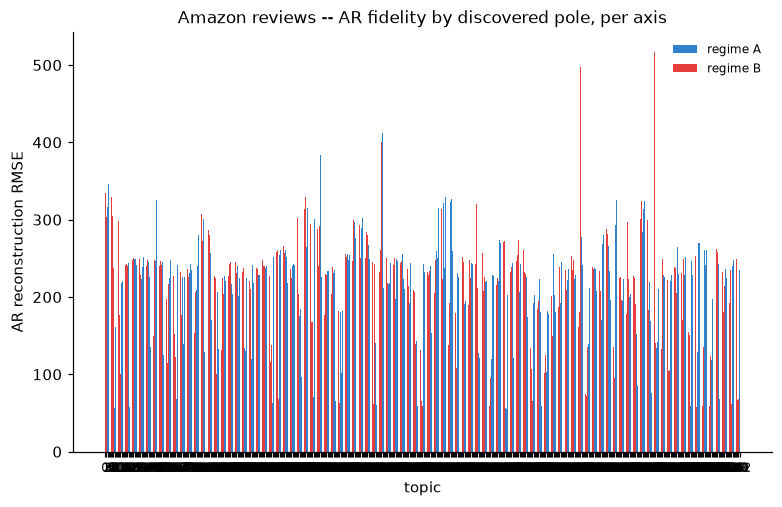

In [43]:
# -> figures/21_nla_pole_contrast.*
fig = V.plot_pole_rmse_contrast(contrast_df.rename(columns={"axis_id": "cluster"}),
                                title="Amazon reviews -- AR fidelity by discovered pole, per axis")
show_fig(store, "21_nla_pole_contrast", fig)

In [44]:
# NLA.pole_prototypes_table -> topolm/nla.py
# -> tables/topol_nla_pole_prototypes.csv
proto_df = NLA.pole_prototypes_table(nla_result, data, vocab, data["texts"],
                                     data["topic_ids"], data["pole_labels"],
                                     n_neighbors=3, layer_id_map=layer_id_map)
proto_df = proto_df.rename(columns={"cluster": "axis_id"}).merge(axis_index, on="axis_id", how="left")
store.save_table("topol_nla_pole_prototypes", proto_df)
display(proto_df)

,axis_id,pole,n,decoded_prototype,nearest_real_docs,topic,contrast_index,l_star,layer_id,effect_size_at_lstar,split_half_cos,n_docs
0,0,A,609,"<unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> un <unk> <unk> personally , tony <un...",k.d. lang on Smoking - Who Cares? It's readily apparent that k.d. lang doesn't realize || Ahead ...,0,1,20,10,1.147746,0.997728,1285
1,0,B,676,<unk> is a hit ! ! ! this is a great album that <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> ...,"Amazing, this CD is the traditional Bonnie Raitt I love Bonnie Raitt and all her || Her best yet...",0,1,20,10,1.147746,0.997728,1285
2,1,A,687,<unk> is a <unk> on the radio lover i have heard so i rate this album . i finally learned that s...,The Way They Did The Things They Did I have had the pleasure of listening || Her best yet!! Iron...,0,2,20,10,0.870738,0.996825,1285
3,1,B,598,"<unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> un <unk> <unk> personally , tony <un...",Ahead of its time Amazing CD that has never ceased being in my musical rotation || Second To Non...,0,2,20,10,0.870738,0.996825,1285
4,2,A,642,"<unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> un <unk> <unk> personally , to...",k.d. lang on Smoking - Who Cares? It's readily apparent that k.d. lang doesn't realize || Not cr...,0,3,20,10,1.012284,0.995826,1285
...,...,...,...,...,...,...,...,...,...,...,...,...
1081,540,B,101,<unk> ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! !,"Best ""#@&%;!"" Game Ever !! I have to say, I've never laughed harder at any || This is crap If I ...",13,51,12,6,0.830279,0.978199,220
1082,541,A,111,this game is fun ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! !,Great Game this game is great. Many people did get mad that they could no || wow I have to admit...,13,52,12,6,0.751999,0.881389,220
1083,541,B,109,"this game is a blast , do not buy this game . the game is <unk> , but the gameplay is <unk> , but","cool stuff,few bugs Battlefront is a good game. But there are a few problems. One || jesus chris...",13,52,12,6,0.751999,0.881389,220
1084,542,A,116,"this game is a blast with all , move the price to get <unk> , but the gameplay itself is just as...",A game with laughable graphics! The only game I'm familiar with here out of the || The Bigs is b...,13,53,2,1,0.750607,0.919517,220


In [45]:
# NLA.direction_sweep_table -> topolm/nla.py
# -> tables/topol_nla_direction_sweep.csv
sweep_df = NLA.direction_sweep_table(nla_result, data, vocab, data["topic_ids"], data["pole_labels"],
                                     n_steps=5, layer_id_map=layer_id_map)
store.save_table("topol_nla_direction_sweep", sweep_df)
display(sweep_df.head(15))

,cluster,alpha,pole_side,decoded
0,0,-0.3,A,"<unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> un <unk> <unk> personally , tony <un..."
1,0,0.1,between,"<unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> un <unk> <unk> personally , tony <un..."
2,0,0.5,between,<unk> <unk> <unk> is a <unk> cd . . . . . . . . . . . . . . . . .
3,0,0.9,between,<unk> is a hit ! ! ! this is a great album that <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> ...
4,0,1.3,B,<unk> is a hit ! ! ! this is a great album that <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> ...
5,1,-0.3,A,<unk> is a <unk> cd ! this cd is the single worst band ever ! i learned a <unk> <unk> who put he...
6,1,0.1,between,<unk> is a <unk> on the radio lover i have heard so many albums that i heard him in this show . ...
7,1,0.5,between,<unk> <unk> <unk> is a <unk> cd . . . . . . . . . . . . . . . . .
8,1,0.9,between,"<unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> un <unk> <unk> personally , tony <un..."
9,1,1.3,B,"<unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> un <unk> <unk> personally , to..."





In [47]:
# NLA.pole_direction_summary -> topolm/nla.py
# -> tables/topol_nla_pole_direction_summary.csv, figures/22_nla_pole_direction_summary.*
summary_df = NLA.pole_direction_summary(
    proto_df.rename(columns={"axis_id": "cluster"}), sweep_df, max_words=8)
store.save_table("topol_nla_pole_direction_summary", summary_df)

fig = V.plot_pole_direction_summary(
    summary_df, title="Amazon reviews -- discovered-axis semantic drift, per axis")
show_fig(store, "22_nla_pole_direction_summary", fig)

### Per topic and across topics

`axis_index`/`contrast_df` carry both a `topic` column (the original UMAP/
Leiden topic) and an `axis_id` (this section's own per-axis unit), so both
views come from the SAME trained model and the SAME table -- "per topic" is
just grouping by `topic`; "across topics" is the ungrouped table itself.

In [48]:
per_topic_ar = contrast_df.groupby("topic").agg(
    n_axes=("axis_id", "nunique"),
    mean_rmse_gap=("rmse_gap_B_minus_A", "mean"),
).reset_index()
display(per_topic_ar)

print("across all topics:")
print("  mean |rmse_gap_B_minus_A| =", round(contrast_df["rmse_gap_B_minus_A"].abs().mean(), 4))
print("  overall AR RMSE / R^2    =", round(ar_result["overall_rmse"], 4),
      "/", round(ar_result["overall_r2"], 4))

,topic,n_axes,mean_rmse_gap
0,0,45,-6.106786
1,1,35,2.884121
2,2,36,4.893616
3,3,40,-0.793855
4,4,42,-0.594116
5,5,43,0.516253
6,6,41,0.895517
7,7,36,-0.052801
8,8,40,-1.029338
9,9,43,2.410177


across all topics:
  mean |rmse_gap_B_minus_A| = 13.7126
  overall AR RMSE / R^2    = 242.9496 / 0.7409


## 9 - Summary: everything saved in this run

Every object from Parts 1-8 lives in ONE run directory, under a `topol_*`
(axis discovery) or `topol_nla_*` (per-axis NLA) key, reloadable by name
(`store.load_object`/`load_array`/`load_json`, or `load_table` above for
CSVs).

In [ ]:
print("run dir:", store.dir)
print()
print("entries in this run:")
for k, kind in sorted(store.list_entries().items()):
    print(f"  [{kind:9s}] {k}")

run dir: /home/users/g/gomeztei/topol_3/scr/runs/amazon_reviews_pipeline_2

entries in this run:
  [figure   ] 01_layer_selection
  [figure   ] 02_field_2d
  [figure   ] 15_activation_exclusion
  [figure   ] 16_depth_profiles_example_topic
  [figure   ] 17_gate_stability
  [figure   ] 18_pooled_spectrum
  [figure   ] 19_pooled_field_of_axes
  [figure   ] 20_baseline_layer_agreement
  [figure   ] 20b_sentiment_alignment
  [figure   ] 21_nla_pole_contrast
  [figure   ] 22_nla_pole_direction_summary
  [array    ] cluster_labels
  [config   ] config
  [array    ] coords_2d
  [json     ] data_meta
  [array    ] embeddings
  [pickle   ] field
  [array    ] labels
  [json     ] layer_selection
  [pickle   ] texts
  [pickle   ] topics
  [array_f16] topol_acts_L0
  [array_f16] topol_acts_L10
  [array_f16] topol_acts_L12
  [array_f16] topol_acts_L14
  [array_f16] topol_acts_L16
  [array_f16] topol_acts_L18
  [array_f16] topol_acts_L2
  [array_f16] topol_acts_L20
  [array_f16] topol_acts_L22
  [a

: 

### Where to go next

* If **v_CB^t's own sentiment alignment** (Part 6, `cb_corr_rating`) is weak
  for most topics, the human-coded CB itself is not cleanly tracking rating
  there -- read its extreme reviews (Part 6) before trusting anything
  downstream. If **identification** rarely matches the axis most correlated
  with rating (`identification_matches_most_sentiment_aligned`), some other
  discovered axis is the better sentiment estimator in that topic -- look at
  it directly rather than assuming the cosine-nearest one to v_CB^t is best.
* The \|cos\|-direction families (Part 5) tell you which axes point the same
  way; `pipeline_2_part2.ipynb`'s semantic families tell you which axes
  CONTRAST SIMILAR VOCABULARY -- read both, since they empirically capture
  different structure (near-chance agreement between the two), not the same
  structure twice.
* The **text extremes** (Part 7) and **NLA prototypes/sweeps** (Part 8) are
  the actual interpretation route for any axis you want to report on: read
  the reviews, read the decoded words, and check they tell the same story
  before writing anything up. NLA's free-generated text (the direction
  sweep especially, at interpolated/extrapolated points never seen in
  training) is frequently degenerate (`<unk>`-heavy, repeated boilerplate)
  -- treat `nearest_real_docs` in the prototypes table as the trustworthy
  half of that section, and the decoded sweep text as a rough qualitative
  hint only.
* See `README_pipeline_2.md` (next to this notebook) for the full map from
  every part above to its `topolm` module and its `scripts/0N_*.py` equivalent.